<a href="https://colab.research.google.com/github/2303a510c3/Quantum-Computing/blob/main/Quantum_Circuit_Designer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install -q "qiskit[visualization]" qiskit-aer ipywidgets

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

from qiskit_aer import AerSimulator

from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector,
    plot_state_qsphere
)

import ipywidgets as widgets
from IPython.display import display, clear_output

print("======================================")
print(" Quantum Circuit Designer & Simulator ")
print("======================================")
print("Qiskit is ready!")

 Quantum Circuit Designer & Simulator 
Qiskit is ready!


In [11]:
simulator = AerSimulator()

print("Quantum simulator created successfully!")

Quantum simulator created successfully!


In [12]:
# ============================================================
# QUANTUM CIRCUIT DEFINITIONS
# ============================================================

# 1. Identity Circuit
def identity_circuit():
    qc = QuantumCircuit(1)
    qc.id(0)
    return qc


# 2. Pauli-X / NOT Circuit
def x_circuit():
    qc = QuantumCircuit(1)
    qc.x(0)
    return qc


# 3. Pauli-Y Circuit
def y_circuit():
    qc = QuantumCircuit(1)
    qc.y(0)
    return qc


# 4. Pauli-Z Circuit
def z_circuit():
    qc = QuantumCircuit(1)
    qc.z(0)
    return qc


# 5. Hadamard / Superposition Circuit
def h_circuit():
    qc = QuantumCircuit(1)
    qc.h(0)
    return qc


# 6. Phase-S Circuit
def s_circuit():
    qc = QuantumCircuit(1)
    qc.s(0)
    return qc


# 7. Phase-T Circuit
def t_circuit():
    qc = QuantumCircuit(1)
    qc.t(0)
    return qc


# 8. Rx Rotation Circuit
def rx_circuit():
    qc = QuantumCircuit(1)
    qc.rx(np.pi / 2, 0)
    return qc


# 9. Ry Rotation Circuit
def ry_circuit():
    qc = QuantumCircuit(1)
    qc.ry(np.pi / 2, 0)
    return qc


# 10. Rz Rotation Circuit
def rz_circuit():
    qc = QuantumCircuit(1)
    qc.rz(np.pi / 2, 0)
    return qc


# 11. Measurement Circuit
def measurement_circuit():
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.measure(0, 0)
    return qc


# ============================================================
# MULTI-QUBIT CIRCUITS
# ============================================================

# 12. CNOT Circuit
def cnot_circuit():
    qc = QuantumCircuit(2)
    qc.x(0)
    qc.cx(0, 1)
    return qc


# 13. Controlled-Z Circuit
def cz_circuit():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.h(1)
    qc.cz(0, 1)
    return qc


# 14. SWAP Circuit
def swap_circuit():
    qc = QuantumCircuit(2)
    qc.x(0)
    qc.swap(0, 1)
    return qc


# 15. Toffoli / CCX Circuit
def toffoli_circuit():
    qc = QuantumCircuit(3)
    qc.x(0)
    qc.x(1)
    qc.ccx(0, 1, 2)
    return qc


# 16. Bell State Circuit
def bell_circuit():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    return qc


# 17. GHZ State Circuit
def ghz_circuit():
    qc = QuantumCircuit(3)
    qc.h(0)
    qc.cx(0, 1)
    qc.cx(1, 2)
    return qc


print("All 17 quantum circuits created successfully!")

All 17 quantum circuits created successfully!


In [13]:
# ============================================================
# CIRCUIT DATABASE
# ============================================================

circuits = {
    "Identity": identity_circuit,
    "Pauli-X": x_circuit,
    "Pauli-Y": y_circuit,
    "Pauli-Z": z_circuit,
    "Hadamard": h_circuit,
    "Phase-S": s_circuit,
    "Phase-T": t_circuit,
    "Rx": rx_circuit,
    "Ry": ry_circuit,
    "Rz": rz_circuit,
    "Measurement": measurement_circuit,
    "CNOT": cnot_circuit,
    "CZ": cz_circuit,
    "SWAP": swap_circuit,
    "Toffoli": toffoli_circuit,
    "Bell State": bell_circuit,
    "GHZ State": ghz_circuit
}

print("Available circuits:")
print()

for i, name in enumerate(circuits.keys(), 1):
    print(f"{i}. {name}")

print()
print("Total circuits:", len(circuits))

Available circuits:

1. Identity
2. Pauli-X
3. Pauli-Y
4. Pauli-Z
5. Hadamard
6. Phase-S
7. Phase-T
8. Rx
9. Ry
10. Rz
11. Measurement
12. CNOT
13. CZ
14. SWAP
15. Toffoli
16. Bell State
17. GHZ State

Total circuits: 17


In [14]:
# ============================================================
# SIMULATION FUNCTIONS
# ============================================================

def get_statevector(qc):
    """
    Calculate the quantum statevector.
    """

    circuit = qc.copy()

    # Remove measurement operations
    circuit.remove_final_measurements(inplace=True)

    state = Statevector.from_instruction(circuit)

    return state


def get_measurement_counts(qc, shots=1024):
    """
    Run measurement simulation.
    """

    circuit = qc.copy()

    # Add measurement to all qubits
    if circuit.num_clbits == 0:
        circuit.measure_all()

    compiled = transpile(
        circuit,
        simulator
    )

    result = simulator.run(
        compiled,
        shots=shots,
        seed_simulator=42
    ).result()

    counts = result.get_counts()

    return counts


def get_probabilities(qc):
    """
    Calculate theoretical probabilities
    from the statevector.
    """

    state = get_statevector(qc)

    probabilities = np.abs(state.data) ** 2

    n = qc.num_qubits

    result = {}

    for i, probability in enumerate(probabilities):

        state_name = format(
            i,
            f"0{n}b"
        )

        result[state_name] = probability

    return result


print("Simulation functions created!")

Simulation functions created!


Quantum Circuit:


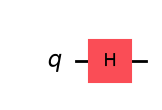


Statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Probabilities:
|0> = 0.5000
|1> = 0.5000

Measurement:
{'0': 526, '1': 498}


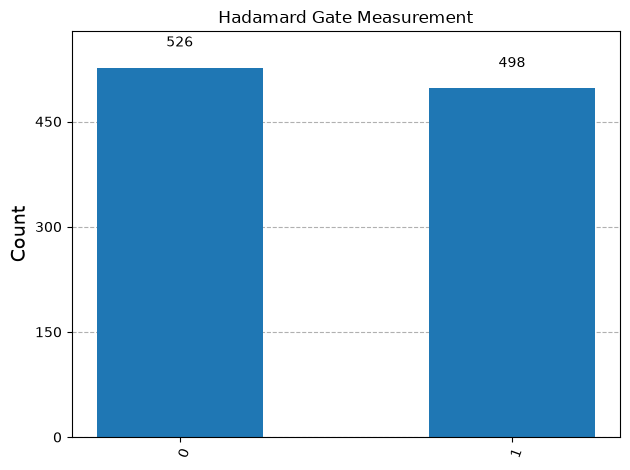

In [15]:
qc = h_circuit()

print("Quantum Circuit:")
display(qc.draw("mpl"))

print("\nStatevector:")

state = get_statevector(qc)

print(state)

print("\nProbabilities:")

probabilities = get_probabilities(qc)

for state_name, probability in probabilities.items():
    print(
        f"|{state_name}> = "
        f"{probability:.4f}"
    )

print("\nMeasurement:")

counts = get_measurement_counts(
    qc,
    shots=1024
)

print(counts)

display(
    plot_histogram(
        counts,
        title="Hadamard Gate Measurement"
    )
)

In [16]:
# ============================================================
# COMPLETE CIRCUIT ANALYZER
# ============================================================

def analyze_circuit(name, shots=1024):

    qc = circuits[name]()

    print("=" * 70)
    print(f"QUANTUM CIRCUIT: {name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Circuit
    # --------------------------------------------------------

    print("\n1. CIRCUIT DIAGRAM")
    display(qc.draw("mpl"))

    # --------------------------------------------------------
    # Statevector
    # --------------------------------------------------------

    print("\n2. STATEVECTOR")

    state = get_statevector(qc)

    print(state)

    # --------------------------------------------------------
    # Probabilities
    # --------------------------------------------------------

    print("\n3. THEORETICAL PROBABILITIES")

    probabilities = get_probabilities(qc)

    for state_name, probability in probabilities.items():

        if probability > 0.000001:

            print(
                f"|{state_name}> : "
                f"{probability:.4f}"
            )

    # --------------------------------------------------------
    # Bloch Sphere
    # --------------------------------------------------------

    if qc.num_qubits <= 3:

        print("\n4. BLOCH SPHERE")

        display(
            plot_bloch_multivector(
                state
            )
        )

    # --------------------------------------------------------
    # Q-Sphere
    # --------------------------------------------------------

    if qc.num_qubits <= 3:

        print("\n5. Q-SPHERE")

        display(
            plot_state_qsphere(
                state
            )
        )

    # --------------------------------------------------------
    # Measurement
    # --------------------------------------------------------

    print("\n6. MEASUREMENT RESULTS")

    counts = get_measurement_counts(
        qc,
        shots
    )

    print(counts)

    display(
        plot_histogram(
            counts,
            title=f"{name} - Measurement Results"
        )
    )

    print("\nAnalysis completed.")

    return {
        "circuit": qc,
        "statevector": state,
        "probabilities": probabilities,
        "counts": counts
    }

QUANTUM CIRCUIT: Bell State

1. CIRCUIT DIAGRAM


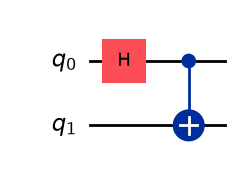


2. STATEVECTOR
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

3. THEORETICAL PROBABILITIES
|00> : 0.5000
|11> : 0.5000

4. BLOCH SPHERE


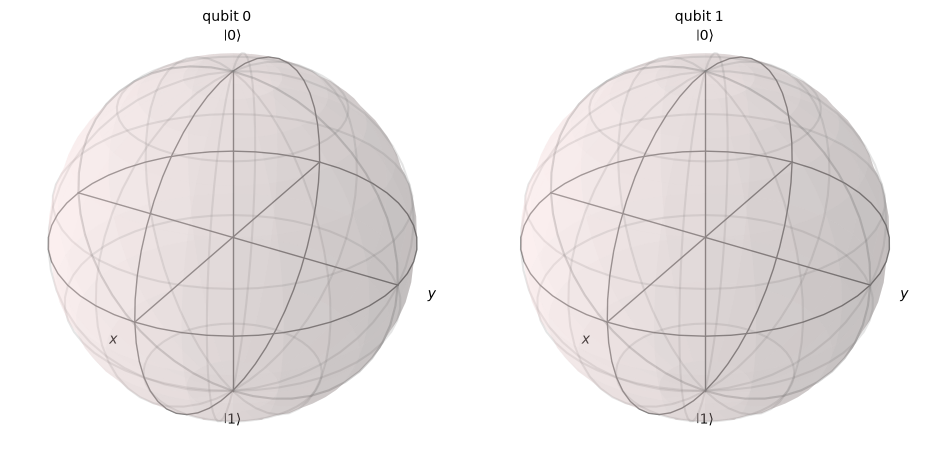


5. Q-SPHERE


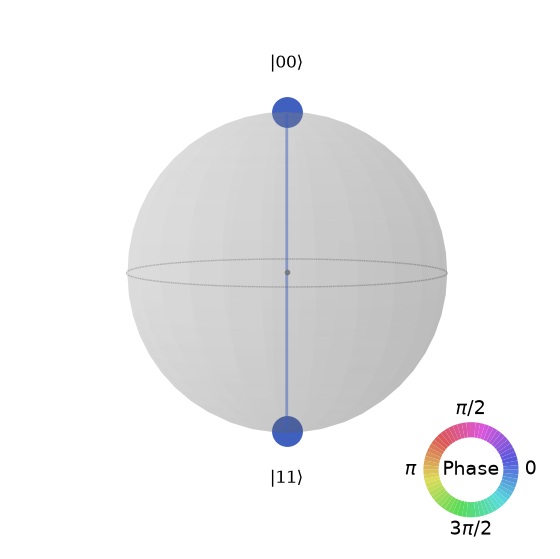


6. MEASUREMENT RESULTS
{'11': 503, '00': 521}


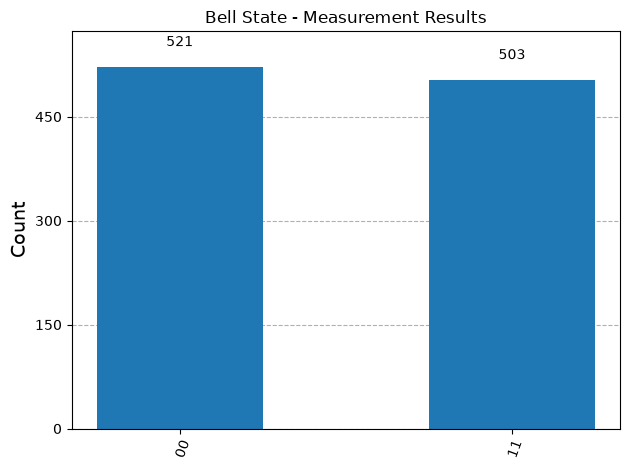


Analysis completed.


In [17]:
bell_result = analyze_circuit(
    "Bell State",
    shots=1024
)

QUANTUM CIRCUIT: GHZ State

1. CIRCUIT DIAGRAM


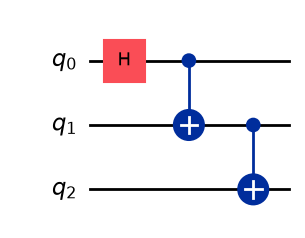


2. STATEVECTOR
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.70710678+0.j],
            dims=(2, 2, 2))

3. THEORETICAL PROBABILITIES
|000> : 0.5000
|111> : 0.5000

4. BLOCH SPHERE


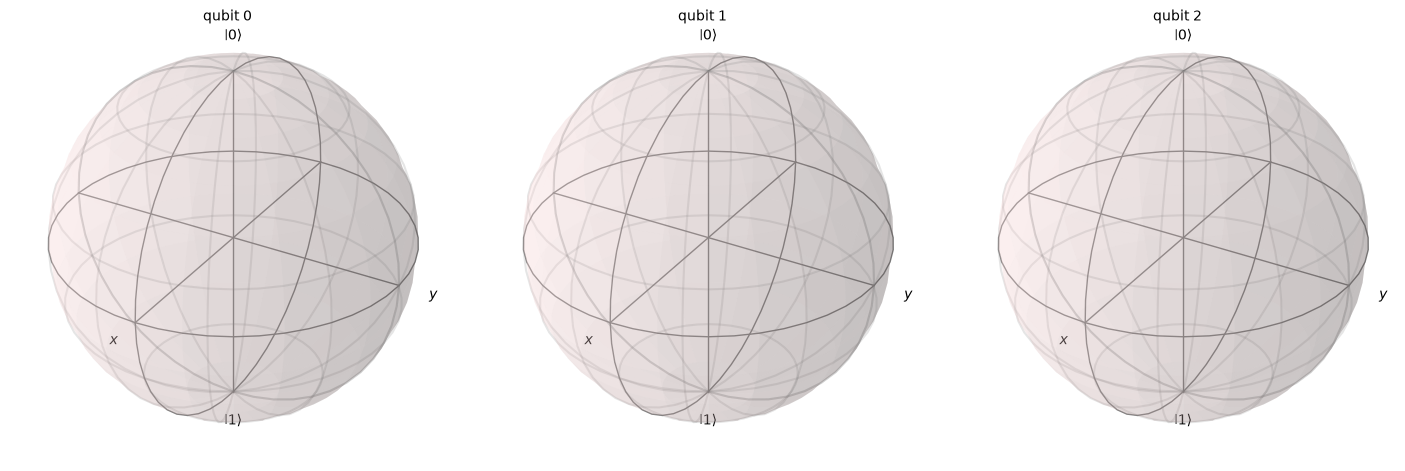


5. Q-SPHERE


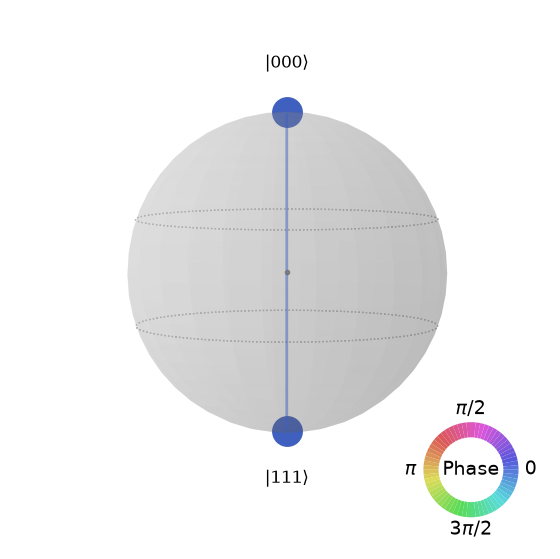


6. MEASUREMENT RESULTS
{'000': 490, '111': 534}


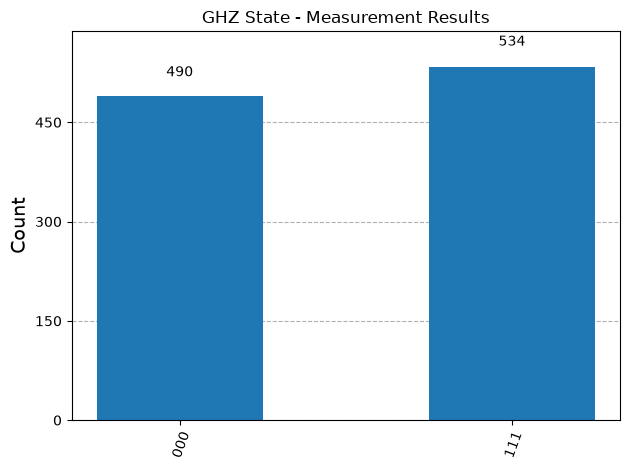


Analysis completed.


In [18]:
ghz_result = analyze_circuit(
    "GHZ State",
    shots=1024
)



Identity


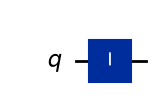



Pauli-X


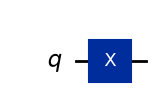



Pauli-Y


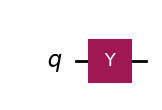



Pauli-Z


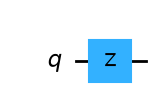



Hadamard


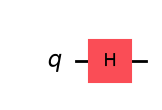



Phase-S


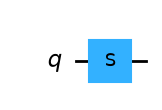



Phase-T


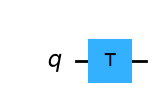



Rx


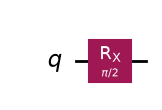



Ry


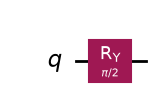



Rz


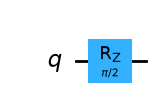



Measurement


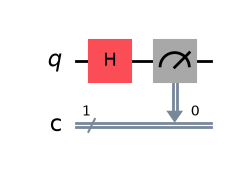



CNOT


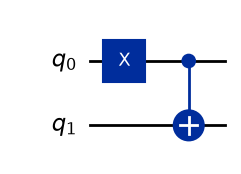



CZ


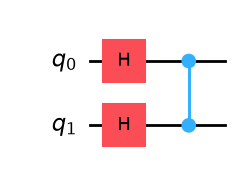



SWAP


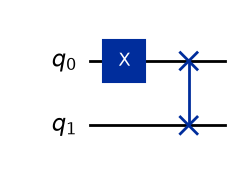



Toffoli


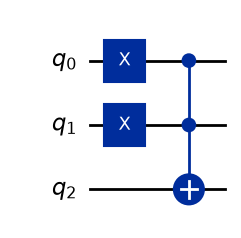



Bell State


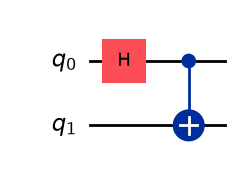



GHZ State


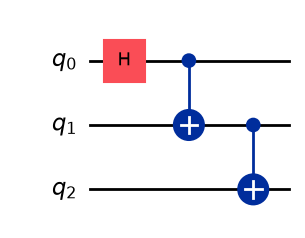

In [19]:
# ============================================================
# DISPLAY ALL CIRCUITS
# ============================================================

for name in circuits:

    print("\n")
    print("=" * 60)
    print(name)
    print("=" * 60)

    qc = circuits[name]()

    display(
        qc.draw("mpl")
    )

In [20]:
# ============================================================
# RUN ALL CIRCUITS
# ============================================================

all_results = {}

for name in circuits:

    qc = circuits[name]()

    counts = get_measurement_counts(
        qc,
        shots=1024
    )

    all_results[name] = counts

    print(
        f"{name:15} -> {counts}"
    )

Identity        -> {'0': 1024}
Pauli-X         -> {'1': 1024}
Pauli-Y         -> {'1': 1024}
Pauli-Z         -> {'0': 1024}
Hadamard        -> {'0': 526, '1': 498}
Phase-S         -> {'0': 1024}
Phase-T         -> {'0': 1024}
Rx              -> {'0': 526, '1': 498}
Ry              -> {'0': 526, '1': 498}
Rz              -> {'0': 1024}
Measurement     -> {'0': 526, '1': 498}
CNOT            -> {'11': 1024}
CZ              -> {'11': 231, '01': 272, '00': 243, '10': 278}
SWAP            -> {'10': 1024}
Toffoli         -> {'111': 1024}
Bell State      -> {'11': 503, '00': 521}
GHZ State       -> {'000': 490, '111': 534}


In [21]:
# ============================================================
# RESULTS TABLE
# ============================================================

rows = []

for circuit_name, counts in all_results.items():

    total = sum(counts.values())

    for state, count in counts.items():

        probability = count / total

        rows.append({
            "Circuit": circuit_name,
            "State": state,
            "Counts": count,
            "Probability": round(
                probability,
                4
            )
        })


results_df = pd.DataFrame(rows)

display(results_df)

,Circuit,State,Counts,Probability
0,Identity,0,1024,1.0000
1,Pauli-X,1,1024,1.0000
2,Pauli-Y,1,1024,1.0000
3,Pauli-Z,0,1024,1.0000
4,Hadamard,0,526,0.5137
5,Hadamard,1,498,0.4863
6,Phase-S,0,1024,1.0000
7,Phase-T,0,1024,1.0000
8,Rx,0,526,0.5137
9,Rx,1,498,0.4863


In [22]:
# ============================================================
# THEORETICAL VS SIMULATED
# ============================================================

comparison_rows = []

for circuit_name, counts in all_results.items():

    theoretical = get_probabilities(
        circuits[circuit_name]()
    )

    total = sum(counts.values())

    states = set(theoretical.keys()) | set(counts.keys())

    for state in states:

        theoretical_probability = theoretical.get(
            state,
            0
        )

        simulated_probability = counts.get(
            state,
            0
        ) / total

        error = abs(
            theoretical_probability -
            simulated_probability
        )

        comparison_rows.append({

            "Circuit": circuit_name,

            "State": state,

            "Theoretical": round(
                theoretical_probability,
                4
            ),

            "Simulated": round(
                simulated_probability,
                4
            ),

            "Absolute Error": round(
                error,
                4
            )
        })


comparison_df = pd.DataFrame(
    comparison_rows
)

display(comparison_df)

,Circuit,State,Theoretical,Simulated,Absolute Error
0,Identity,0,1.00,1.0000,0.0000
1,Identity,1,0.00,0.0000,0.0000
2,Pauli-X,0,0.00,0.0000,0.0000
3,Pauli-X,1,1.00,1.0000,0.0000
4,Pauli-Y,0,0.00,0.0000,0.0000
5,Pauli-Y,1,1.00,1.0000,0.0000
6,Pauli-Z,0,1.00,1.0000,0.0000
7,Pauli-Z,1,0.00,0.0000,0.0000
8,Hadamard,0,0.50,0.5137,0.0137
9,Hadamard,1,0.50,0.4863,0.0137


Original Circuit:


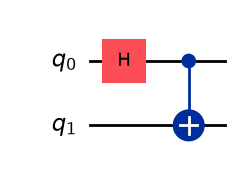


Transpilation Analysis:


,Optimization Level,Depth,Gate Count,Operations
0,0,2,2,"OrderedDict({'h': 1, 'cx': 1})"
1,1,2,2,"OrderedDict({'h': 1, 'cx': 1})"
2,2,2,2,"OrderedDict({'h': 1, 'cx': 1})"
3,3,2,2,"OrderedDict({'h': 1, 'cx': 1})"


In [23]:
# ============================================================
# TRANSPILATION ANALYSIS
# ============================================================

qc = bell_circuit()

transpilation_data = []

for level in range(4):

    transpiled_qc = transpile(
        qc,
        simulator,
        optimization_level=level
    )

    transpilation_data.append({

        "Optimization Level": level,

        "Depth": transpiled_qc.depth(),

        "Gate Count": transpiled_qc.size(),

        "Operations": str(
            transpiled_qc.count_ops()
        )
    })


transpilation_df = pd.DataFrame(
    transpilation_data
)

print("Original Circuit:")
display(
    qc.draw("mpl")
)

print("\nTranspilation Analysis:")

display(
    transpilation_df
)

In [24]:
# ============================================================
# INTERACTIVE QUANTUM CIRCUIT DESIGNER
# ============================================================

circuit_selector = widgets.Dropdown(

    options=list(circuits.keys()),

    value="Bell State",

    description="Circuit:",

    style={
        "description_width": "initial"
    }
)


shots_selector = widgets.IntSlider(

    value=1024,

    min=100,

    max=5000,

    step=100,

    description="Shots:",

    style={
        "description_width": "initial"
    }
)


run_button = widgets.Button(

    description="RUN SIMULATION",

    button_style="success",

    icon="play"
)


interface_output = widgets.Output()

In [25]:
def run_designer(button):

    with interface_output:

        clear_output(wait=True)

        selected_circuit = (
            circuit_selector.value
        )

        shots = (
            shots_selector.value
        )

        qc = circuits[
            selected_circuit
        ]()

        print("=" * 70)

        print(
            "QUANTUM CIRCUIT DESIGNER"
        )

        print("=" * 70)

        print(
            "\nSelected Circuit:",
            selected_circuit
        )

        print(
            "Number of Shots:",
            shots
        )

        # ----------------------------------------------------
        # Circuit
        # ----------------------------------------------------

        print(
            "\nCIRCUIT DIAGRAM"
        )

        display(
            qc.draw("mpl")
        )

        # ----------------------------------------------------
        # Statevector
        # ----------------------------------------------------

        state = get_statevector(qc)

        print(
            "\nSTATEVECTOR"
        )

        print(state)

        # ----------------------------------------------------
        # Probabilities
        # ----------------------------------------------------

        print(
            "\nPROBABILITIES"
        )

        probabilities = get_probabilities(
            qc
        )

        for state_name, probability in probabilities.items():

            if probability > 0.000001:

                print(
                    f"|{state_name}> = "
                    f"{probability:.4f}"
                )

        # ----------------------------------------------------
        # Measurement
        # ----------------------------------------------------

        counts = get_measurement_counts(
            qc,
            shots
        )

        print(
            "\nMEASUREMENT RESULTS"
        )

        print(counts)

        display(
            plot_histogram(
                counts,
                title=(
                    f"{selected_circuit} "
                    "Measurement"
                )
            )
        )

        # ----------------------------------------------------
        # Bloch Sphere
        # ----------------------------------------------------

        if qc.num_qubits <= 3:

            print(
                "\nBLOCH SPHERE"
            )

            display(
                plot_bloch_multivector(
                    state
                )
            )

        # ----------------------------------------------------
        # Q-Sphere
        # ----------------------------------------------------

        if qc.num_qubits <= 3:

            print(
                "\nQ-SPHERE"
            )

            display(
                plot_state_qsphere(
                    state
                )
            )

        print(
            "\nSimulation completed successfully!"
        )


run_button.on_click(
    run_designer
)

In [26]:
display(
    widgets.VBox([

        circuit_selector,

        shots_selector,

        run_button,

        interface_output

    ])
)

In [27]:
# ============================================================
# AUTOMATED TESTING
# ============================================================

def test_all_circuits():

    for name, function in circuits.items():

        qc = function()

        assert isinstance(
            qc,
            QuantumCircuit
        )

    return True


def test_x_gate():

    qc = x_circuit()

    state = get_statevector(qc)

    probabilities = np.abs(
        state.data
    ) ** 2

    assert np.isclose(
        probabilities[1],
        1.0
    )

    return True


def test_hadamard():

    qc = h_circuit()

    state = get_statevector(qc)

    probabilities = np.abs(
        state.data
    ) ** 2

    assert np.isclose(
        probabilities[0],
        0.5
    )

    assert np.isclose(
        probabilities[1],
        0.5
    )

    return True


def test_bell():

    qc = bell_circuit()

    state = get_statevector(qc)

    probabilities = np.abs(
        state.data
    ) ** 2

    assert np.isclose(
        probabilities[0],
        0.5
    )

    assert np.isclose(
        probabilities[3],
        0.5
    )

    return True


def test_ghz():

    qc = ghz_circuit()

    state = get_statevector(qc)

    probabilities = np.abs(
        state.data
    ) ** 2

    assert np.isclose(
        probabilities[0],
        0.5
    )

    assert np.isclose(
        probabilities[7],
        0.5
    )

    return True


print("Automated tests created!")

Automated tests created!


In [28]:
# ============================================================
# RUN AUTOMATED TESTS
# ============================================================

tests = {

    "All Circuits": test_all_circuits,

    "Pauli-X": test_x_gate,

    "Hadamard": test_hadamard,

    "Bell State": test_bell,

    "GHZ State": test_ghz
}


test_results = []


for test_name, test_function in tests.items():

    try:

        test_function()

        test_results.append({

            "Test": test_name,

            "Status": "PASS"

        })

    except Exception as error:

        test_results.append({

            "Test": test_name,

            "Status": "FAIL",

            "Error": str(error)

        })


test_df = pd.DataFrame(
    test_results
)

display(test_df)

,Test,Status
0,All Circuits,PASS
1,Pauli-X,PASS
2,Hadamard,PASS
3,Bell State,PASS
4,GHZ State,PASS


In [29]:
# ============================================================
# NOISY SIMULATION
# ============================================================

from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error
)


noise_model = NoiseModel()


one_qubit_error = depolarizing_error(
    0.01,
    1
)


two_qubit_error = depolarizing_error(
    0.02,
    2
)


noise_model.add_all_qubit_quantum_error(
    one_qubit_error,
    ["x", "y", "z", "h"]
)


noise_model.add_all_qubit_quantum_error(
    two_qubit_error,
    ["cx"]
)


print("Noise model created successfully!")

Noise model created successfully!


Noisy Bell State:
{'01': 6, '10': 4, '00': 520, '11': 494}


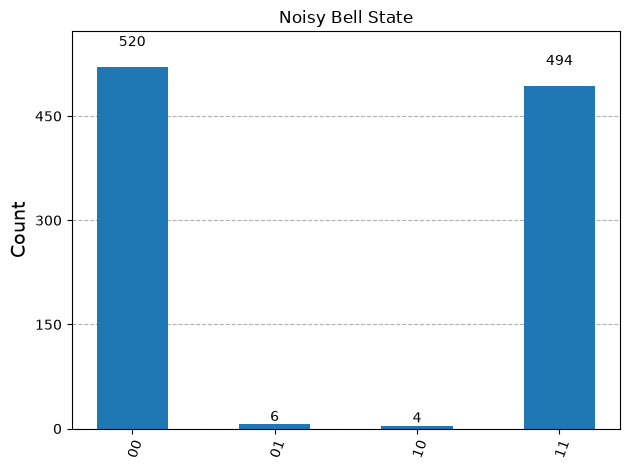

In [30]:
# ============================================================
# NOISY BELL STATE
# ============================================================

qc = bell_circuit()

qc.measure_all()


noisy_simulator = AerSimulator(
    noise_model=noise_model
)


compiled = transpile(
    qc,
    noisy_simulator
)


result = noisy_simulator.run(
    compiled,
    shots=1024,
    seed_simulator=42
).result()


noisy_counts = result.get_counts()


print("Noisy Bell State:")
print(noisy_counts)


display(
    plot_histogram(
        noisy_counts,
        title="Noisy Bell State"
    )
)

In [31]:
# ============================================================
# SAVE RESULTS
# ============================================================

results_df.to_csv(
    "measurement_results.csv",
    index=False
)

comparison_df.to_csv(
    "theoretical_vs_simulated.csv",
    index=False
)

transpilation_df.to_csv(
    "transpilation_analysis.csv",
    index=False
)

test_df.to_csv(
    "automated_test_results.csv",
    index=False
)

print("All result files saved!")

All result files saved!


In [32]:
# ============================================================
# CREATE README
# ============================================================

readme = """
# Quantum Circuit Designer and Simulator

## Project

Quantum Circuit Designer and Simulator using Qiskit.

## Implemented Circuits

1. Identity
2. Pauli-X
3. Pauli-Y
4. Pauli-Z
5. Hadamard
6. Phase-S
7. Phase-T
8. Rx
9. Ry
10. Rz
11. Measurement
12. CNOT
13. CZ
14. SWAP
15. Toffoli
16. Bell State
17. GHZ State

## Features

- Quantum circuit design
- Quantum circuit visualization
- Statevector simulation
- Measurement simulation
- Measurement histograms
- Bloch sphere visualization
- Q-sphere visualization
- Theoretical vs simulated comparison
- Transpilation analysis
- Automated testing
- Noisy simulation
- Interactive circuit designer

## Technologies

Python
Qiskit
Qiskit Aer
NumPy
Pandas
Matplotlib
IPyWidgets

## Author

Shah Alam
"""

with open(
    "README.md",
    "w"
) as file:

    file.write(
        readme
    )

print("README.md created!")

README.md created!


In [33]:
requirements = """
qiskit[visualization]
qiskit-aer
numpy
pandas
matplotlib
ipywidgets
"""

with open(
    "requirements.txt",
    "w"
) as file:

    file.write(
        requirements.strip()
    )

print("requirements.txt created!")

requirements.txt created!


In [34]:
import os

print("PROJECT FILES")
print("=" * 50)

for file in os.listdir("."):

    if os.path.isfile(file):

        print(file)

PROJECT FILES
automated_test_results.csv
requirements.txt
README.md
theoretical_vs_simulated.csv
measurement_results.csv
transpilation_analysis.csv
